In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split


print("PyTorch:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch: 2.14.0+rocm10.1.0
Device: cuda


In [2]:

colums = ["center", "left", "right", "steering", "throttle", "brake", "speed"]
#lake
files = pd.read_csv("data/driving_log.csv", header=None, names=colums)
#jungle
files = pd.read_csv("data-jungle-new/driving_log.csv", header=None, names=colums)


data = files[["center", "left", "right"]]
y = files[["steering"]]
print(data.head())


                                              center  \
0  /home/peter/Desktop/self-driving-car/data-jung...   
1  /home/peter/Desktop/self-driving-car/data-jung...   
2  /home/peter/Desktop/self-driving-car/data-jung...   
3  /home/peter/Desktop/self-driving-car/data-jung...   
4  /home/peter/Desktop/self-driving-car/data-jung...   

                                                left  \
0  /home/peter/Desktop/self-driving-car/data-jung...   
1  /home/peter/Desktop/self-driving-car/data-jung...   
2  /home/peter/Desktop/self-driving-car/data-jung...   
3  /home/peter/Desktop/self-driving-car/data-jung...   
4  /home/peter/Desktop/self-driving-car/data-jung...   

                                               right  
0  /home/peter/Desktop/self-driving-car/data-jung...  
1  /home/peter/Desktop/self-driving-car/data-jung...  
2  /home/peter/Desktop/self-driving-car/data-jung...  
3  /home/peter/Desktop/self-driving-car/data-jung...  
4  /home/peter/Desktop/self-driving-car/data-jung..

In [3]:
image_dir = Path("data-jungle-new/IMG")

# Convert center, left, right columns into rows
files["frame_id"] = np.arange(len(files))

data = files.melt(
    id_vars=["frame_id", "steering"],
    value_vars=["center", "left", "right"],
    var_name="camera",
    value_name="filename"
)

# Correct steering angles (negative = left)
correction = 0.2

data["steering"] += data["camera"].map({
    "center": 0,
    "left": -correction,
    "right": correction
})

# Load and crop images
images = []

for filename in data["filename"]:
    image_path = image_dir / Path(str(filename).strip()).name

    with Image.open(image_path) as image:
        cropped = image.crop((0, 55, image.width, image.height))
        images.append(np.array(cropped.convert("RGB")))

data["image"] = images


Straight: 37.11%
Left:     31.88%
Right:    31.00%


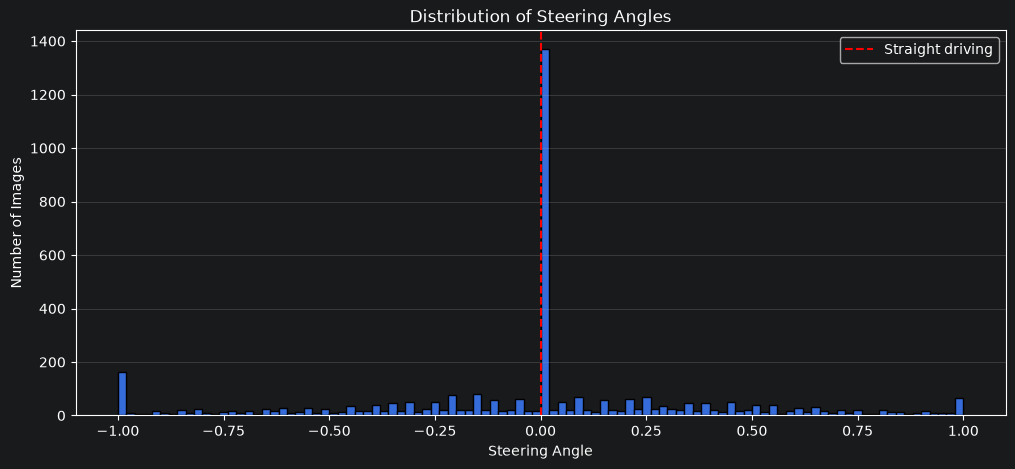

In [4]:
steering = pd.to_numeric(files["steering"], errors="coerce").dropna()

plt.figure(figsize=(12, 5))

plt.hist(steering, bins=100, edgecolor="black")

plt.xlabel("Steering Angle")
plt.ylabel("Number of Images")
plt.title("Distribution of Steering Angles")
plt.axvline(0, color="red", linestyle="--", label="Straight driving")
plt.legend()
plt.grid(axis="y", alpha=0.3)

straight = (steering.abs() < 0.05).sum()
left = (steering <= -0.05).sum()
right = (steering >= 0.05).sum()

total = len(steering)

print(f"Straight: {straight / total * 100:.2f}%")
print(f"Left:     {left / total * 100:.2f}%")
print(f"Right:    {right / total * 100:.2f}%")
plt.show()

data is wayyyy to centered for proper training. this fixes it by keeping only 30% of it

In [5]:
# Split original frame IDs, not individual images
frame_ids = files["frame_id"].to_numpy()

train_ids, test_ids = train_test_split(
    frame_ids,
    test_size=0.2,
    random_state=42
)

# All three cameras from one frame stay together
train_data = data[data["frame_id"].isin(train_ids)]
test_data = data[data["frame_id"].isin(test_ids)]

X_train = np.stack(train_data["image"].to_numpy())
y_train = train_data["steering"].to_numpy(dtype=np.float32)

X_test = np.stack(test_data["image"].to_numpy())
y_test = test_data["steering"].to_numpy(dtype=np.float32)

# Normalize and convert NHWC -> NCHW
X_train = X_train.transpose(0, 3, 1, 2).astype(np.float32) / 255.0
X_test = X_test.transpose(0, 3, 1, 2).astype(np.float32) / 255.0

# Undersample straight-driving examples (training only)
straight_indices = np.where(y_train == 0)[0]
turning_indices = np.where(y_train != 0)[0]

rng = np.random.default_rng(42)

straight_sample = rng.choice(
    straight_indices,
    size=int(len(straight_indices) * 0.70),
    replace=False
)

keep_indices = np.concatenate([
    straight_sample,
    turning_indices
])

rng.shuffle(keep_indices)

X_train = X_train[keep_indices]
y_train = y_train[keep_indices]

# Verify there is no frame overlap
assert set(train_data["frame_id"]).isdisjoint(
    set(test_data["frame_id"])
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Train/test frame overlap: 0")
print(f"Straight driving: {(y_train == 0).mean() * 100:.2f}%")

Training images: 8928
Testing images: 2319
Train/test frame overlap: 0
Straight driving: 9.01%


In [6]:
import torch.nn as nn

class DrivingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.relu = nn.ReLU()
        self.conv1 = nn.Conv2d(3, 24, 5, 2)
        self.conv2 = nn.Conv2d(24, 36, 5, 2)
        self.conv3 = nn.Conv2d(36, 48, 5, 2)
        self.conv4 = nn.Conv2d(48, 64, 3, 1)
        self.conv5 = nn.Conv2d(64, 64, 3, 1)
        self.fc1 = nn.Linear(12672, 100)
        self.fc2 = nn.Linear(100, 50)
        self.fc3 = nn.Linear(50, 10)
        self.fc4 = nn.Linear(10, 1)


    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.relu(self.conv5(x))
        x = torch.flatten(x, start_dim=1)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.fc4(x)
        return x

In [7]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DrivingCNN().to(device)


X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)


from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)


In [8]:
epochs = 500
patience = 25

best_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(epochs):

    # Training
    model.train()
    train_loss = 0

    for images, steering in train_loader:
        images = images.to(device)
        steering = steering.to(device).view(-1, 1)

        optimizer.zero_grad()

        predictions = model(images)
        loss = criterion(predictions, steering)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)

    # Evaluation
    model.eval()
    test_loss = 0

    with torch.no_grad():
        for images, steering in test_loader:
            images = images.to(device)
            steering = steering.to(device).view(-1, 1)

            predictions = model(images)
            loss = criterion(predictions, steering)

            test_loss += loss.item() * images.size(0)

    # Average loss across entire evaluation dataset
    test_loss /= len(test_loader.dataset)

    # Save best model and check early stopping
    if test_loss < best_loss:
        best_loss = test_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), "best_driving_model.pth")

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Test Loss: {test_loss:.5f} | "
        f"Patience: {epochs_without_improvement}/{patience}"
    )

    # Stop training if no improvement for 10 consecutive epochs
    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

print(f"Best evaluation loss: {best_loss:.5f}")

MIOpen: Warning [OpenRuntimeLibraryForDevice] CK grouped conv library not found for device gfx1032: libMIOpenCKGroupedConv_gfx1032.so: cannot open shared object file: No such file or directory


Epoch 1/500 | Train Loss: 0.21336 | Test Loss: 0.20365 | Patience: 0/25
Epoch 2/500 | Train Loss: 0.20442 | Test Loss: 0.18913 | Patience: 0/25
Epoch 3/500 | Train Loss: 0.16138 | Test Loss: 0.12280 | Patience: 0/25
Epoch 4/500 | Train Loss: 0.12212 | Test Loss: 0.11303 | Patience: 0/25
Epoch 5/500 | Train Loss: 0.10895 | Test Loss: 0.09741 | Patience: 0/25
Epoch 6/500 | Train Loss: 0.09846 | Test Loss: 0.09227 | Patience: 0/25
Epoch 7/500 | Train Loss: 0.09061 | Test Loss: 0.08064 | Patience: 0/25
Epoch 8/500 | Train Loss: 0.08127 | Test Loss: 0.07641 | Patience: 0/25
Epoch 9/500 | Train Loss: 0.07516 | Test Loss: 0.07593 | Patience: 0/25
Epoch 10/500 | Train Loss: 0.06949 | Test Loss: 0.07222 | Patience: 0/25
Epoch 11/500 | Train Loss: 0.06807 | Test Loss: 0.07025 | Patience: 0/25
Epoch 12/500 | Train Loss: 0.06341 | Test Loss: 0.06749 | Patience: 0/25
Epoch 13/500 | Train Loss: 0.05941 | Test Loss: 0.06554 | Patience: 0/25
Epoch 14/500 | Train Loss: 0.05615 | Test Loss: 0.06543 | Pa

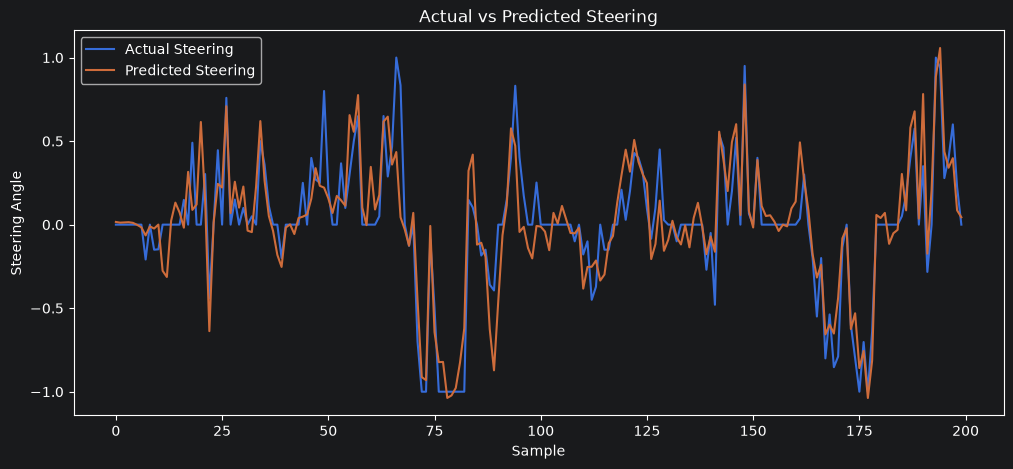

In [10]:
model.eval()

with torch.no_grad():
    predictions = model(
        X_test_tensor.to(device)
    ).cpu().numpy().flatten()

plt.figure(figsize=(12, 5))

plt.plot(y_test[:200], label="Actual Steering")
plt.plot(predictions[:200], label="Predicted Steering")

plt.xlabel("Sample")
plt.ylabel("Steering Angle")
plt.title("Actual vs Predicted Steering")
plt.legend()
plt.show()